# An explainable mortgage default model

## Business objective

The model gives each mortgage application a **probability of default**. A higher score means the applicant resembles historical borrowers who were more likely to default. The bank can choose a cutoff above which an application receives additional review or is rejected.

## Why logistic regression?

Logistic regression is suitable for this proof of concept because it directly produces probabilities, performs strongly on later applications, and is easier to explain and review than a complex black-box model. More sophisticated models could be compared later, but complexity is only worthwhile if it produces a meaningful improvement.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

## 1. Use past applications to predict later applications

The model learns from 2008–2015 applications and is checked on 2016 applications. The 2017–2018 test period remains untouched until the final model is fixed. This mirrors how the bank would use historical cases to assess future applicants.

In [2]:
repo_root = Path.cwd()
if not (repo_root / ".env").exists():
    repo_root = repo_root.parent
load_dotenv(repo_root / ".env")

database_url = URL.create(
    drivername="postgresql+psycopg", username=os.environ["PGUSER"],
    password=os.environ["PGPASSWORD"], host=os.environ["PGHOST"],
    port=int(os.environ["PGPORT"]), database=os.environ["PGDATABASE"],
)
query = """
SELECT source_row_id, income, loan_amount, term_length, install_to_inc,
       occup, schufa, num_applic, obs_date, target_var
FROM public.mortgage_default
ORDER BY source_row_id
"""
engine = create_engine(database_url)
try:
    mortgage_data = pd.read_sql_query(query, engine)
finally:
    engine.dispose()

mortgage_data["obs_date"] = pd.to_datetime(mortgage_data["obs_date"], errors="raise")
mortgage_data["target_var"] = mortgage_data["target_var"].astype("Int64")
labelled = mortgage_data.loc[mortgage_data["target_var"].notna()].copy()
years = labelled["obs_date"].dt.year
training_data = labelled.loc[years.le(2015)].copy()
validation_data = labelled.loc[years.eq(2016)].copy()
test_ids = set(labelled.loc[years.isin([2017, 2018]), "source_row_id"])

assert len(training_data) == 6_422
assert len(validation_data) == 838
assert set(training_data["source_row_id"]).isdisjoint(test_ids)
assert set(validation_data["source_row_id"]).isdisjoint(test_ids)
pd.DataFrame({
    "Period": ["Training: 2008–2015", "Validation: 2016", "Test: 2017–2018"],
    "Records": [len(training_data), len(validation_data), len(test_ids)],
    "Use": ["Learn the model", "Check and choose the model", "Final evaluation only"],
})

,Period,Records,Use
0,Training: 2008–2015,6422,Learn the model
1,Validation: 2016,838,Check and choose the model
2,Test: 2017–2018,1641,Final evaluation only


## 2. Prepare the application information

Missing numeric values are replaced with the training median, while a separate flag records that the value was originally missing. Numeric scales are standardized so one large unit does not dominate the model. Occupation and applicant count are converted into model-readable categories, with missing values labelled `Unknown`.

In [3]:
numeric_features = ["income", "loan_amount", "term_length", "install_to_inc", "schufa"]
categorical_features = ["occupation", "number_of_applicants"]

def model_inputs(data):
    inputs = data[numeric_features].copy()
    occupation = data["occup"].astype("string")
    inputs["occupation"] = pd.Series(
        occupation.to_numpy(dtype=object, na_value=np.nan), index=data.index
    )
    applicants = data["num_applic"].astype("Int64").astype("string")
    inputs["number_of_applicants"] = pd.Series(
        applicants.to_numpy(dtype=object, na_value=np.nan), index=data.index
    )
    return inputs

X_train = model_inputs(training_data)
y_train = training_data["target_var"].astype(int)
X_validation = model_inputs(validation_data)
y_validation = validation_data["target_var"].astype(int)

numeric_preparation = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
category_preparation = Pipeline([
    ("fill_missing", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(
        handle_unknown="ignore", sparse_output=False, drop=["Employee", "1"]
    )),
])
preprocessor = ColumnTransformer([
    ("numbers", numeric_preparation, numeric_features),
    ("missing_flags", MissingIndicator(features="all"), numeric_features),
    ("categories", category_preparation, categorical_features),
])

model = Pipeline([
    ("prepare", preprocessor),
    ("predict_default", LogisticRegression(max_iter=2_000, random_state=42)),
])

## 3. Train the model and produce default scores

The model learns relationships from the training period and then assigns each 2016 applicant a probability between 0% and 100%.

In [4]:
model.fit(X_train, y_train)
validation_scores = model.predict_proba(X_validation)[:, 1]
assert np.isfinite(validation_scores).all()
print(f"Created {len(validation_scores):,} validation default scores.")

Created 838 validation default scores.


## 4. Does the model assign higher scores to actual defaults?

ROC-AUC measures how often the model ranks a defaulting applicant above a non-defaulting applicant. A score of 50% means no ranking skill; 100% means perfect ranking.

In [5]:
baseline_scores = np.full(len(y_validation), y_train.mean())
baseline_auc = roc_auc_score(y_validation, baseline_scores)
model_auc = roc_auc_score(y_validation, validation_scores)

performance_summary = pd.DataFrame({
    "Approach": ["Historical average only", "Logistic regression"],
    "ROC-AUC": [baseline_auc, model_auc],
    "Plain-language result": [
        "Cannot rank applicants",
        "Usually gives higher scores to applicants who default",
    ],
})
performance_summary.style.format({"ROC-AUC": "{:.1%}"})

,Approach,ROC-AUC,Plain-language result
0,Historical average only,50.0%,Cannot rank applicants
1,Logistic regression,91.9%,Usually gives higher scores to applicants who default


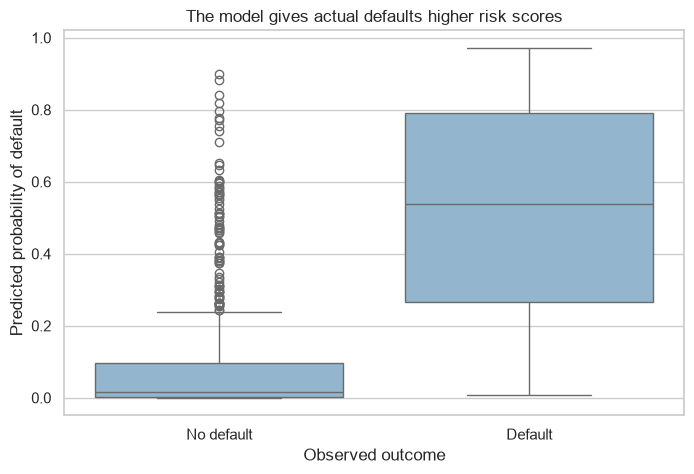

,Applicants,Average_score,Median_score
Observed outcome,,,
Default,146,52.1%,53.9%
No default,692,9.0%,1.5%


In [6]:
score_results = pd.DataFrame({
    "Predicted default probability": validation_scores,
    "Observed outcome": y_validation.map({0: "No default", 1: "Default"}),
})

figure, axis = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=score_results, x="Observed outcome", y="Predicted default probability",
    order=["No default", "Default"], color="#8AB6D6", ax=axis,
)
axis.set_title("The model gives actual defaults higher risk scores")
axis.set_ylabel("Predicted probability of default")
plt.show()

score_results.groupby("Observed outcome")["Predicted default probability"].agg(
    Applicants="size", Average_score="mean", Median_score="median"
).style.format({"Average_score": "{:.1%}", "Median_score": "{:.1%}"})

## 5. The bank must choose the risk cutoff

A lower cutoff catches more defaults but rejects more applicants who would have repaid. A higher cutoff approves more applicants but misses more defaults. The table illustrates this trade-off; it does not recommend a cutoff.

In [7]:
def cutoff_summary(cutoff):
    reject = validation_scores >= cutoff
    tn, fp, fn, tp = confusion_matrix(y_validation, reject.astype(int), labels=[0, 1]).ravel()
    return {
        "Risk cutoff": cutoff,
        "Applications rejected": int(reject.sum()),
        "Rejection rate": reject.mean(),
        "Defaults caught": tp,
        "Defaults missed": fn,
        "Non-defaults rejected": fp,
    }

cutoff_table = pd.DataFrame([cutoff_summary(value) for value in [0.10, 0.15, 0.20, 0.25]])
cutoff_table.style.format({"Risk cutoff": "{:.0%}", "Rejection rate": "{:.1%}"})

,Risk cutoff,Applications rejected,Rejection rate,Defaults caught,Defaults missed,Non-defaults rejected
0,10%,305,36.4%,134,12,171
1,15%,261,31.1%,126,20,135
2,20%,218,26.0%,117,29,101
3,25%,192,22.9%,111,35,81


## 6. Main model drivers

The model's strongest relationships agree with the exploratory analysis. These are historical associations after accounting for the other included variables; they do not prove that a characteristic causes default.

In [8]:
feature_names = model.named_steps["prepare"].get_feature_names_out()
coefficients = dict(zip(feature_names, model.named_steps["predict_default"].coef_[0]))
driver_definitions = [
    ("Higher SCHUFA score", "numbers__schufa"),
    ("Higher income", "numbers__income"),
    ("Worker rather than Employee", "categories__occupation_Worker"),
    ("Two applicants rather than one", "categories__number_of_applicants_2"),
]
driver_table = pd.DataFrame([
    {
        "Applicant characteristic": label,
        "Relationship with predicted risk": (
            "Higher predicted risk" if coefficients[name] > 0 else "Lower predicted risk"
        ),
    }
    for label, name in driver_definitions
])
driver_table

,Applicant characteristic,Relationship with predicted risk
0,Higher SCHUFA score,Lower predicted risk
1,Higher income,Lower predicted risk
2,Worker rather than Employee,Higher predicted risk
3,Two applicants rather than one,Lower predicted risk


## Conclusion

Logistic regression is a strong proof-of-concept model: it produces understandable default probabilities and achieved **91.9% ROC-AUC** on later 2016 applications. The model can support decisions, but it should not automatically determine them without an agreed cutoff, fairness review, monitoring, and human oversight.

The next modelling step is to choose a cutoff rule using the bank's costs and risk tolerance. After every choice is fixed, the model should be evaluated once on the untouched 2017–2018 test period.

### Appendix support

Additional checks of probability quality and performance on the minority default class are summarized in [`appendix/model_diagnostics.md`](appendix/model_diagnostics.md). They support the result without being required for the main explanation.

## More sophisticated alternatives

Decision trees, random forests, and gradient-boosted trees can capture more complicated relationships automatically. They may improve performance, especially for nonlinear patterns, but are harder to explain and govern. They are reasonable future comparisons; the current logistic model is preferable for the proof of concept because it already combines strong performance with transparency.